In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [ ]:
df = pd.read_csv('BTC_Price.csv')
#Validasi dataset >1000
print('--- INFORMASI AWAL DATASET ---')
print(f'Shape Data (Baris, Kolom): {df.shape}')
print(
    f'Apakah baris sudah lebih dari 1000? {"Iya" if len(df) >= 1000 else "Tidak"}'
)
print(df.head(), '\n')

--- INFORMASI AWAL DATASET ---
Shape Data (Baris, Kolom): (2836, 7)
Apakah baris sudah lebih dari 1000? Iya
         Date         Open         High          Low        Close  \
0  2017-01-01   963.658020  1003.080017   958.698975   998.325012   
1  2017-01-02   998.617004  1031.390015   996.702026  1021.750000   
2  2017-01-03  1021.599976  1044.079956  1021.599976  1043.839966   
3  2017-01-04  1044.400024  1159.420044  1044.400024  1154.729980   
4  2017-01-05  1156.729980  1191.099976   910.416992  1013.380005   

     Adj Close     Volume  
0   998.325012  147775008  
1  1021.750000  222184992  
2  1043.839966  185168000  
3  1154.729980  344945984  
4  1013.380005  510199008   



In [ ]:
# Mengubah kolom 'Date' menjadi tipe data datetime agar bisa diurutkan secara kronologis
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

In [ ]:
# Membersihkan baris yang memiliki nilai kosong (Missing Values)
df = df.dropna().reset_index(drop=True)

In [ ]:
# Logika: Jika harga Close besok > hari ini, maka target = 1 (Naik), jika tidak = 0 (Turun)
df['Next_Close'] = df['Close'].shift(-1)
df['Target'] = np.where(df['Next_Close'] > df['Close'], 1, 0)

# Menambahkan fitur teknikal sederhana (Moving Average 20 hari) untuk membantu model belajar
df['MA_20'] = df['Close'].rolling(window=20).mean()

# Membuang baris yang menjadi NaN akibat proses shift(-1) dan rolling
df = df.dropna().reset_index(drop=True)

print(f'Total baris data setelah cleaning & feature engineering: {len(df)}')

Total baris data setelah cleaning & feature engineering: 2816


In [ ]:
# Kolom fitur (X) yang digunakan untuk prediksi
features = ['Open', 'High', 'Low', 'Close', 'Volume', 'MA_20']
X = df[features]

# Kolom target (y) yang bersifat kategorikal (0 dan 1)
y = df['Target']

print(f'Jumlah fitur X: {X.shape[1]} kolom')
print(
    'Distribusi kelas Target (0 = Turun/Tetap, 1 = Naik):'
)
print(y.value_counts(), '\n')

Jumlah fitur X: 6 kolom
Distribusi kelas Target (0 = Turun/Tetap, 1 = Naik):
Target
1    1479
0    1337
Name: count, dtype: int64 



In [ ]:
# Data tidak boleh di-shuffle/acak agar tidak terjadi data leakage!
# Kita gunakan rasio 80% data masa lalu untuk Training dan 20% data terbaru untuk Testing.
train_size = int(len(X) * 0.8)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

print('--- HASIL DATA SPLITTING ---')
print(f'Jumlah Data Training (X_train, y_train): {len(X_train)} baris')
print(f'Jumlah Data Testing (X_test, y_test): {len(X_test)} baris')
print('Data siap digunakan untuk tahap Data Modeling (Algoritma Klasifikasi)!')

--- HASIL DATA SPLITTING ---
Jumlah Data Training (X_train, y_train): 2252 baris
Jumlah Data Testing (X_test, y_test): 564 baris
Data siap digunakan untuk tahap Data Modeling (Algoritma Klasifikasi)!


In [ ]:
# Menggunakan algoritma Random Forest khusus untuk klasifikasi
model = RandomForestClassifier(random_state=42)

# Melatih model menggunakan data training
model.fit(X_train, y_train)
print('Model berhasil dilatih (Training selesai)!')

Model berhasil dilatih (Training selesai)!


In [ ]:
# Memprediksi data test
y_pred = model.predict(X_test)

# Menghitung akurasi dan laporan evaluasi
akurasi = accuracy_score(y_test, y_pred)

print('\n--- HASIL EVALUASI MODEL KLASIFIKASI ---')
print(f'Akurasi Model: {akurasi * 100:.2f}%')
print('\nClassification Report:')
print(classification_report(y_test, y_pred))


--- HASIL EVALUASI MODEL KLASIFIKASI ---
Akurasi Model: 49.82%

Classification Report:
              precision    recall  f1-score   support

           0       0.49      0.53      0.51       277
           1       0.51      0.46      0.48       287

    accuracy                           0.50       564
   macro avg       0.50      0.50      0.50       564
weighted avg       0.50      0.50      0.50       564



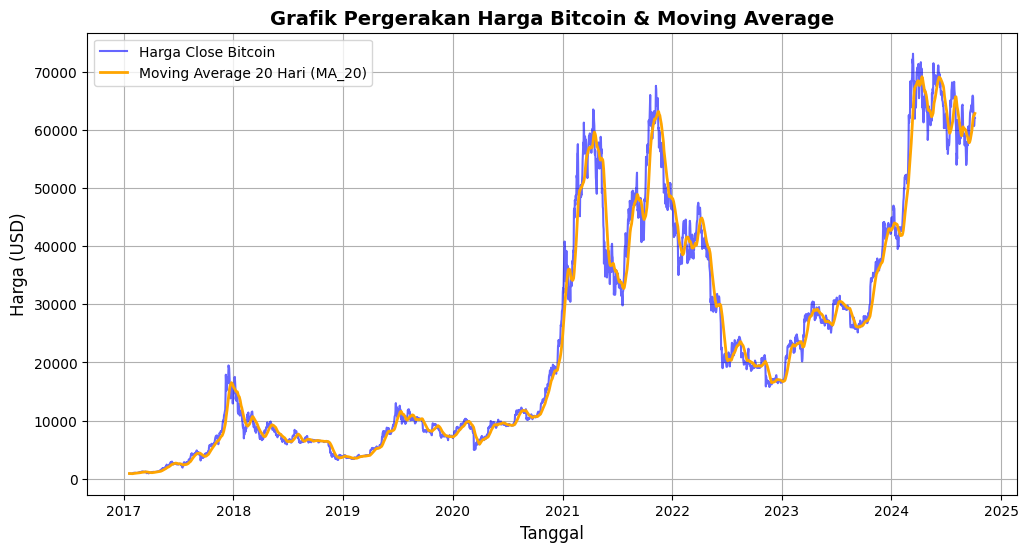

In [ ]:
# Mengatur ukuran tampilan grafik
plt.figure(figsize=(12, 6))

# Plot harga Close asli
plt.plot(
    df['Date'],
    df['Close'],
    label='Harga Close Bitcoin',
    color='blue',
    alpha=0.6,
)

# Plot indikator Moving Average 20 hari
plt.plot(
    df['Date'],
    df['MA_20'],
    label='Moving Average 20 Hari (MA_20)',
    color='orange',
    linewidth=2,
)

# Judul dan label pada grafik
plt.title(
    'Grafik Pergerakan Harga Bitcoin & Moving Average',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Harga (USD)', fontsize=12)
plt.legend()
plt.grid(True)

# Menampilkan grafik
plt.show()